### Imports and paths

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").exists():
    ROOT = cwd
else:
    ROOT = cwd.parent

DATA_DIR = ROOT / "data" / "processed"
TABLE_DIR = ROOT / "outputs" / "tables"
FIGURE_DIR = ROOT / "outputs" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "validation.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

predictions = pd.read_csv(
    TABLE_DIR / "15_test_predictions.csv"
)

with open(DATA_DIR / "experiment_config.json") as f:
    config = json.load(f)

print("Datasets loaded successfully.")

Datasets loaded successfully.


### Check temporal changes in class distribution

,Split,Transactions,Illicit,Illicit_Rate
0,Train,29894,3462,0.115809
1,Validation,7829,675,0.086218
2,Test,8841,408,0.046149


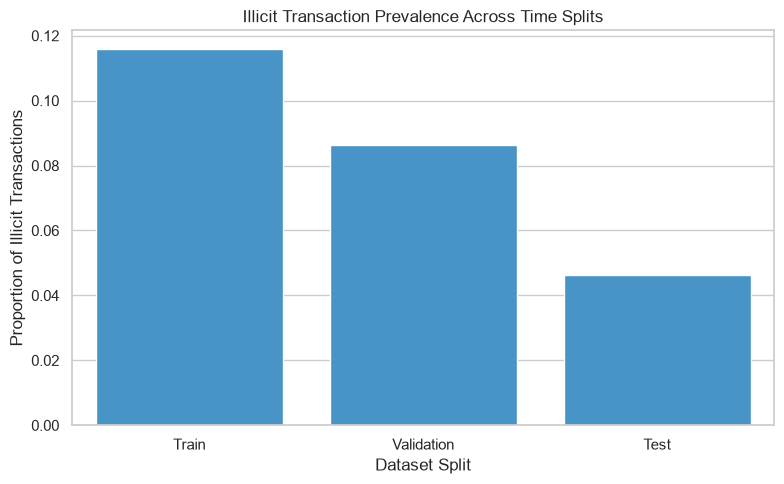

In [2]:
datasets = {
    "Train": train,
    "Validation": val,
    "Test": test
}

rows = []

for name, data in datasets.items():

    rows.append({
        "Split": name,
        "Transactions": len(data),
        "Illicit": int(data["target"].sum()),
        "Illicit_Rate": data["target"].mean()
    })

prevalence_df = pd.DataFrame(rows)

display(prevalence_df)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=prevalence_df,
    x="Split",
    y="Illicit_Rate",
    color="#3498db"
)

plt.title("Illicit Transaction Prevalence Across Time Splits")
plt.ylabel("Proportion of Illicit Transactions")
plt.xlabel("Dataset Split")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "23_temporal_class_prevalence.png",
    dpi=300
)

plt.show()

### Evaluate performance for individual test time steps

In [3]:
temporal_results = []

for model_name, group in predictions.groupby("Model"):

    for step, data in group.groupby("time_step"):

        y_true = data["target"]
        y_pred = data["Prediction"]
        y_prob = data["Probability"]

        result = {
            "Model": model_name,
            "Time_Step": step,
            "Transactions": len(data),
            "Illicit_Count": int(y_true.sum()),
            "Illicit_Rate": y_true.mean(),
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "AP": np.nan,
            "ROC_AUC": np.nan
        }

        if y_true.nunique() == 2:

            result["AP"] = average_precision_score(
                y_true, y_prob
            )

            result["ROC_AUC"] = roc_auc_score(
                y_true, y_prob
            )

        temporal_results.append(result)

temporal_results_df = pd.DataFrame(temporal_results)

display(temporal_results_df)

temporal_results_df.to_csv(
    TABLE_DIR / "18_temporal_test_performance.csv",
    index=False
)

,Model,Time_Step,Transactions,Illicit_Count,Illicit_Rate,Precision,Recall,F1,AP,ROC_AUC
0,Baseline,42,2154,239,0.110956,0.989474,0.786611,0.876457,0.890339,0.961782
1,Baseline,43,1370,24,0.017518,0.000000,0.000000,0.000000,0.037961,0.769502
2,Baseline,44,1591,24,0.015085,0.125000,0.041667,0.062500,0.073151,0.767869
3,Baseline,45,1221,5,0.004095,0.000000,0.000000,0.000000,0.008874,0.730263
4,Baseline,46,712,2,0.002809,0.333333,0.500000,0.400000,0.506410,0.891549
5,Baseline,47,846,22,0.026005,0.000000,0.000000,0.000000,0.036456,0.662511
6,Baseline,48,471,36,0.076433,0.000000,0.000000,0.000000,0.148661,0.761622
7,Baseline,49,476,56,0.117647,0.500000,0.017857,0.034483,0.249045,0.803699
8,Combined,42,2154,239,0.110956,0.994709,0.786611,0.878505,0.890067,0.959105
9,Combined,43,1370,24,0.017518,0.000000,0.000000,0.000000,0.044426,0.792286


### Visualize test performance across time

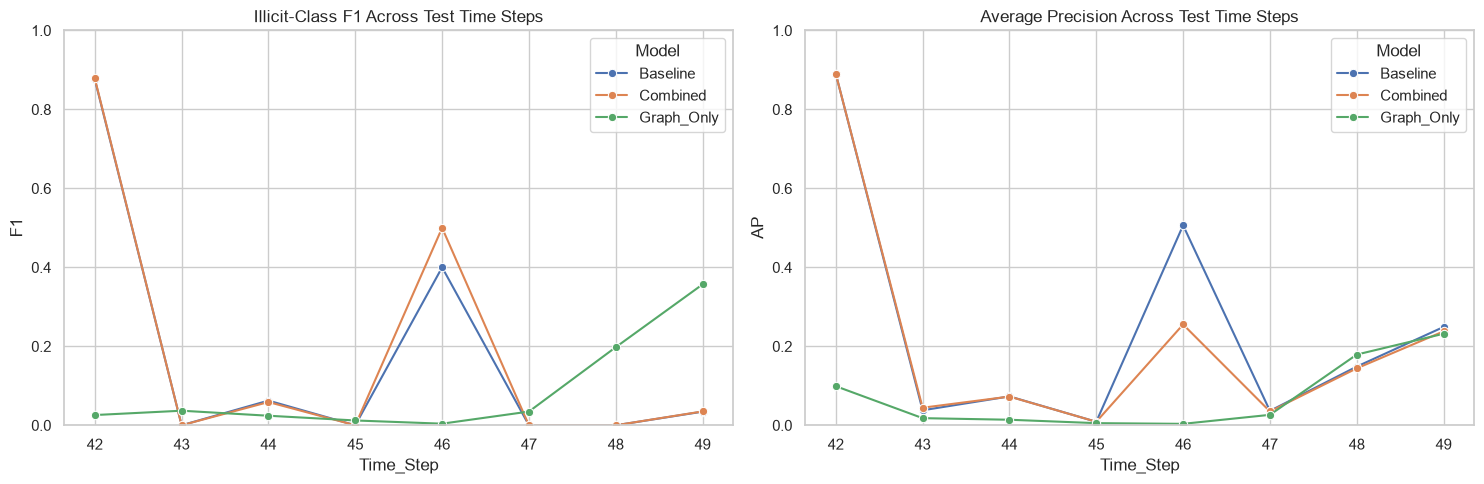

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=temporal_results_df,
    x="Time_Step",
    y="F1",
    hue="Model",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Illicit-Class F1 Across Test Time Steps")
axes[0].set_ylim(0, 1)

sns.lineplot(
    data=temporal_results_df,
    x="Time_Step",
    y="AP",
    hue="Model",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Average Precision Across Test Time Steps")
axes[1].set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "24_temporal_model_performance.png",
    dpi=300
)

plt.show()

### Investigate component size as a time indicator

In [5]:
component_analysis = (
    pd.concat([train, val, test])
    .groupby("time_step")
    .agg(
        component_size=("component_size", "first"),
        unique_component_sizes=("component_size", "nunique"),
        transaction_count=("target", "size")
    )
    .reset_index()
)

display(component_analysis)

print(
    "Time steps with more than one component-size value:",
    (component_analysis["unique_component_sizes"] > 1).sum()
)

print(
    "Unique component sizes:",
    component_analysis["component_size"].nunique()
)

component_analysis.to_csv(
    TABLE_DIR / "19_component_time_analysis.csv",
    index=False
)

,time_step,component_size,unique_component_sizes,transaction_count
0,1,7880,1,2147
1,2,4544,1,1117
2,3,6621,1,1279
3,4,5693,1,1440
4,5,6803,1,1882
5,6,4328,1,485
6,7,6048,1,1203
7,8,4457,1,1165
8,9,4996,1,778
9,10,6727,1,972


Time steps with more than one component-size value: 0
Unique component sizes: 49


### Define graph-feature ablation experiments

In [6]:
graph_features = config["graph_features"]

ablation_groups = {
    "All_Graph": graph_features,

    "Without_Component_Size": [
        col for col in graph_features
        if col != "component_size"
    ],

    "Degree_Only": [
        "in_degree",
        "out_degree",
        "total_degree",
        "degree_difference",
        "degree_ratio"
    ],

    "Degree_And_PageRank": [
        "in_degree",
        "out_degree",
        "total_degree",
        "degree_difference",
        "degree_ratio",
        "pagerank_scaled"
    ]
}

for name, columns in ablation_groups.items():
    print(f"{name}: {len(columns)} features")

All_Graph: 7 features
Without_Component_Size: 6 features
Degree_Only: 5 features
Degree_And_PageRank: 6 features


### Train ablation models and evaluate on validation only

In [7]:
RF_PARAMS = {
    "n_estimators": 250,
    "max_depth": None,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "class_weight": "balanced_subsample",
    "random_state": 42,
    "n_jobs": -1
}

ablation_results = []
ablation_models = {}

for name, columns in ablation_groups.items():

    print("Training:", name)

    model = RandomForestClassifier(**RF_PARAMS)

    model.fit(
        train[columns],
        train["target"]
    )

    probabilities = model.predict_proba(
        val[columns]
    )[:, 1]

    ap = average_precision_score(
        val["target"],
        probabilities
    )

    auc = roc_auc_score(
        val["target"],
        probabilities
    )

    ablation_models[name] = model

    ablation_results.append({
        "Feature_Set": name,
        "Feature_Count": len(columns),
        "Validation_AP": ap,
        "Validation_ROC_AUC": auc
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

ablation_df.to_csv(
    TABLE_DIR / "20_graph_ablation_validation.csv",
    index=False
)

Training: All_Graph
Training: Without_Component_Size
Training: Degree_Only
Training: Degree_And_PageRank


,Feature_Set,Feature_Count,Validation_AP,Validation_ROC_AUC
0,All_Graph,7,0.1312,0.6059
1,Without_Component_Size,6,0.1140,0.5721
2,Degree_Only,5,0.1157,0.6134
3,Degree_And_PageRank,6,0.1140,0.5721


### Visualize graph-feature ablation results

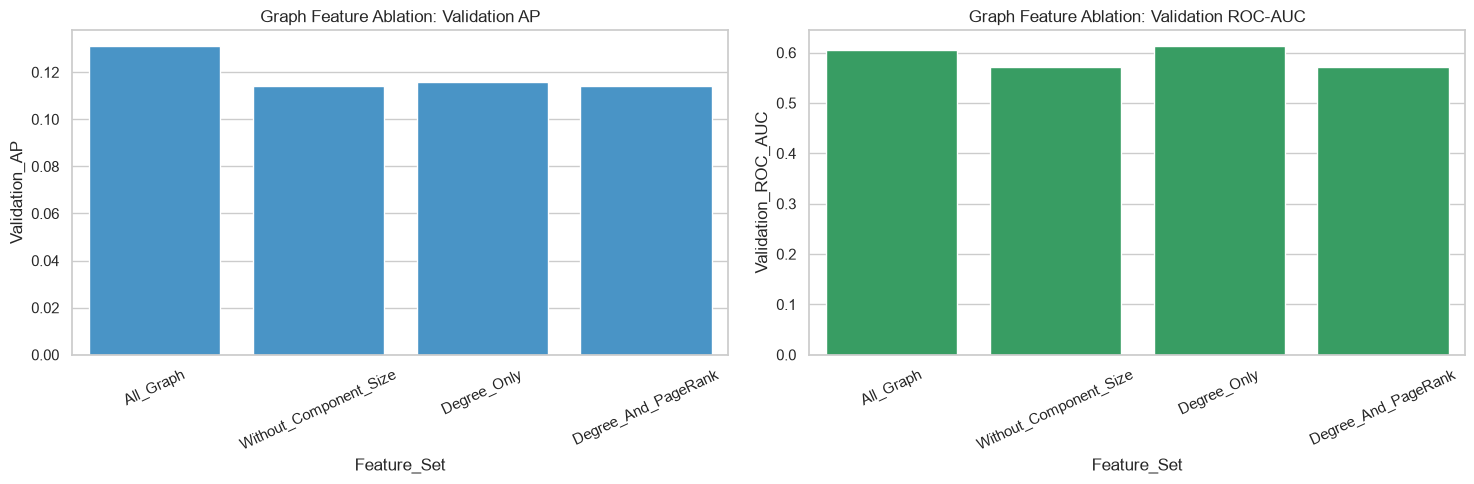

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=ablation_df,
    x="Feature_Set",
    y="Validation_AP",
    color="#3498db",
    ax=axes[0]
)

axes[0].set_title("Graph Feature Ablation: Validation AP")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=ablation_df,
    x="Feature_Set",
    y="Validation_ROC_AUC",
    color="#27ae60",
    ax=axes[1]
)

axes[1].set_title("Graph Feature Ablation: Validation ROC-AUC")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "25_graph_feature_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Summarize temporal robustness

In [9]:
summary = (
    temporal_results_df.groupby("Model")
    .agg(
        Mean_Time_Step_F1=("F1", "mean"),
        Std_Time_Step_F1=("F1", "std"),
        Mean_Time_Step_AP=("AP", "mean"),
        Std_Time_Step_AP=("AP", "std"),
        Mean_Time_Step_ROC_AUC=("ROC_AUC", "mean")
    )
    .reset_index()
)

display(summary.round(4))

summary.to_csv(
    TABLE_DIR / "21_temporal_robustness_summary.csv",
    index=False
)

print(
    "These are unweighted averages of per-time-step metrics, "
    "not pooled test-set metrics."
)


,Model,Mean_Time_Step_F1,Std_Time_Step_F1,Mean_Time_Step_AP,Std_Time_Step_AP,Mean_Time_Step_ROC_AUC
0,Baseline,0.1717,0.3157,0.2439,0.3084,0.7936
1,Combined,0.1841,0.3285,0.2111,0.2896,0.7867
2,Graph_Only,0.0866,0.1257,0.0722,0.0888,0.5258


These are unweighted averages of per-time-step metrics, not pooled test-set metrics.


### Final validation

In [10]:
checks = {
    "Temporal results generated": len(temporal_results_df) > 0,
    "All three original models included": (
        temporal_results_df["Model"].nunique() == 3
    ),
    "Ablation models trained": len(ablation_models) == 4,
    "Ablation results saved": (
        TABLE_DIR / "20_graph_ablation_validation.csv"
    ).exists(),
    "Temporal results saved": (
        TABLE_DIR / "18_temporal_test_performance.csv"
    ).exists(),
    "Robustness summary saved": (
        TABLE_DIR / "21_temporal_robustness_summary.csv"
    ).exists()
}

print("NOTEBOOK 05 VALIDATION")
print("=" * 50)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'}: {name}")

if all(checks.values()):
    print("\nNotebook 05 completed successfully.")

NOTEBOOK 05 VALIDATION
PASS: Temporal results generated
PASS: All three original models included
PASS: Ablation models trained
PASS: Ablation results saved
PASS: Temporal results saved
PASS: Robustness summary saved

Notebook 05 completed successfully.
